In [44]:
import pandas as pd
import numpy as np



from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [45]:
df = pd.read_csv("cancer.csv")
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [46]:
df.corr(numeric_only=True)

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
id,1.000000,0.074626,0.099770,0.073159,0.096893,-0.012968,0.000096,0.050080,0.044158,-0.022114,...,0.064720,0.079986,0.107187,0.010338,-0.002968,0.023203,0.035174,-0.044224,-0.029866,NaN
radius_mean,0.074626,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,...,0.297008,0.965137,0.941082,0.119616,0.413463,0.526911,0.744214,0.163953,0.007066,NaN
texture_mean,0.099770,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,...,0.912045,0.358040,0.343546,0.077503,0.277830,0.301025,0.295316,0.105008,0.119205,NaN
perimeter_mean,0.073159,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,...,0.303038,0.970387,0.941550,0.150549,0.455774,0.563879,0.771241,0.189115,0.051019,NaN
area_mean,0.096893,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,...,0.287489,0.959120,0.959213,0.123523,0.390410,0.512606,0.722017,0.143570,0.003738,NaN
smoothness_mean,-0.012968,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,...,0.036072,0.238853,0.206718,0.805324,0.472468,0.434926,0.503053,0.394309,0.499316,NaN
compactness_mean,0.000096,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,...,0.248133,0.590210,0.509604,0.565541,0.865809,0.816275,0.815573,0.510223,0.687382,NaN
concavity_mean,0.050080,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,...,0.299879,0.729565,0.675987,0.448822,0.754968,0.884103,0.861323,0.409464,0.514930,NaN
concave points_mean,0.044158,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,...,0.292752,0.855923,0.809630,0.452753,0.667454,0.752399,0.910155,0.375744,0.368661,NaN
symmetry_mean,-0.022114,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,...,0.090651,0.219169,0.177193,0.426675,0.473200,0.433721,0.430297,0.699826,0.438413,NaN


In [47]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

In [48]:
X = df[[
    "radius_mean",
    "texture_mean",
    "perimeter_mean",
    "area_mean"
]]
X
y = df["diagnosis"]
y

0      M
1      M
2      M
3      M
4      M
      ..
564    M
565    M
566    M
567    M
568    B
Name: diagnosis, Length: 569, dtype: object

In [49]:
poly = PolynomialFeatures(degree = 2)

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X,y, train_size= 0.2, random_state = 42)

In [51]:
poly_train_X = poly.fit_transform(X_train)
poly_test_X = poly.transform(X_test)
poly_test_X

array([[1.0000000e+00, 1.2470000e+01, 1.8600000e+01, ..., 6.5755881e+03,
        3.9077271e+04, 2.3222761e+05],
       [1.0000000e+00, 1.8940000e+01, 2.1310000e+01, ..., 1.5276960e+04,
        1.3966800e+05, 1.2769000e+06],
       [1.0000000e+00, 1.5460000e+01, 1.9480000e+01, ..., 1.0342890e+04,
        7.6163130e+04, 5.6085121e+05],
       ...,
       [1.0000000e+00, 1.2030000e+01, 1.7930000e+01, ..., 5.7896881e+03,
        3.3936140e+04, 1.9891600e+05],
       [1.0000000e+00, 1.2230000e+01, 1.9560000e+01, ..., 6.1685316e+03,
        3.6206940e+04, 2.1252100e+05],
       [1.0000000e+00, 1.8450000e+01, 2.1910000e+01, ..., 1.4448040e+04,
        1.2921500e+05, 1.1556250e+06]], shape=(456, 15))

In [52]:
print(df.head())


         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  texture_worst  perimeter_worst  area_worst  smoothness

In [53]:
df = df.drop(columns=["Unnamed: 32"])

In [54]:
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

In [55]:
X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"]
y

0      1
1      1
2      1
3      1
4      1
      ..
564    1
565    1
566    1
567    1
568    0
Name: diagnosis, Length: 569, dtype: int64

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.2, random_state=42
)

In [57]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)


In [58]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train_poly, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [59]:
y_pred = model.predict(X_test_poly)  
print(y_pred)

[-6.85605947e-02  1.27530338e-01  1.91496978e-01  2.25715610e+00
  1.03610323e-01 -1.03682576e+01 -6.98990507e+00  1.76737495e+00
 -2.00486354e+00  3.19576107e-01  3.26750264e-01  4.52955342e-01
 -3.92784840e-01  2.11104046e+00 -4.10407256e-01  1.99080405e+00
  9.39056550e-01  2.08523978e-01  5.60134798e-01 -7.70073314e-01
 -1.75235830e+00 -3.70639205e-01 -9.17076488e+00  1.00538148e-01
 -7.56317679e-01  7.72315767e-01 -4.55877112e-02 -8.19311534e-02
 -1.48884248e-01 -2.80113415e+00 -7.99143595e-01 -1.68366567e-01
  1.21425563e-01  2.14551803e-01 -3.63336404e-01 -1.70894472e-01
  1.25055332e+00  4.94618097e-01  3.24592034e+00 -1.37699530e-01
 -3.91805067e-01  2.03301228e+00 -6.57286074e-01  2.37777637e-01
  5.07743024e-02  7.85750883e-01 -4.02050112e-01 -1.51199851e+00
  4.02566570e-01  7.56231708e-01  4.59686604e+00 -5.68913343e+00
 -9.59727185e-02 -1.69066370e-01  8.89204847e-01 -2.61565288e-04
 -3.80229455e-01 -3.91395163e+00 -1.11254198e+00 -7.06483177e-01
 -1.14571356e-01  3.93813

In [60]:
result = pd.DataFrame({
    "actuall" : y_test,
    "predicted" : y_pred
})
result

,actuall,predicted
204,0,-0.068561
70,1,0.127530
131,1,0.191497
431,0,2.257156
540,0,0.103610
...,...,...
417,1,-3.641867
267,0,-0.048503
327,0,0.262534
200,0,0.116277


In [61]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [62]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = mse**0.5
r2 = r2_score(y_test, y_pred)
print("mae : ", mae)
print("mse : ", mse)
print("rmse : ", rmse)
print("r2 : ", r2)

mae :  1.2832560159312003
mse :  7.27837303355468
rmse :  2.697845998858104
r2 :  -30.438217181246902


In [63]:
for i in range(1, 6):
    poly = PolynomialFeatures(degree = i)
    poly_train_X = poly.fit_transform(X_train)
    poly_test_X = poly.transform(X_test)
    model = LinearRegression()
    model.fit(poly_train_X,y_train)
    y_pred = model.predict(poly_test_X)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = mse**0.5
    r2 = r2_score(y_test, y_pred)
    print("mae : ", mae)
    print("mse : ", mse)
    print("rmse : ", rmse)
    print("r2 : ", r2)
    print("="*30)
    

mae :  0.22402199209286505
mse :  0.09854610075342037
rmse :  0.31392053254513375
r2 :  0.5743398004515328
mae :  1.2832560159312003
mse :  7.27837303355468
rmse :  2.697845998858104
r2 :  -30.438217181246902
mae :  4.3257427745651915
mse :  608.1186934432004
rmse :  24.660062721801832
r2 :  -2625.7089455713613
mae :  26.515232464868365
mse :  86577.23429081019
rmse :  294.2400963342865
r2 :  -373960.85686526605
mae :  95.7922217605377
mse :  1326603.6377343938
rmse :  1151.7828084037344
r2 :  -5730133.067634792


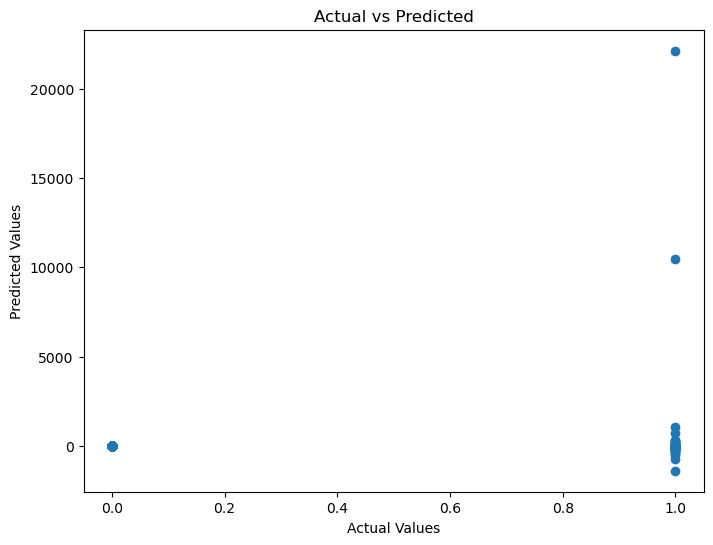

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")

plt.show()